<a href="https://colab.research.google.com/github/sara-iqbal/Forecasting-SEND-demand-Kingston-Richmond-and-Windsor-Maidenhead/blob/main/send_ehcp_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Forecasting SEND demand
### A three-year forecast of Education, Health and Care Plans for Kingston, Richmond and Windsor & Maidenhead

**Author:** Sara Iqbal, MSc Data Science
**Tools:** Python (pandas, NumPy, statsmodels, Matplotlib), SQL (SQLite), Power BI
**Data:** DfE *Education, health and care plans* (SEN2 statutory return), reporting year 2026

## Why this project exists

An **Education, Health and Care Plan (EHCP)** is a legal document setting out the support a child or young person aged 0 to 25 with special educational needs and disabilities (SEND) must receive. Councils have a duty to assess, issue, fund and review every plan once a year.

Demand has been rising fast. In England there were **718,838 plans in January 2026, 12.5% more than a year earlier**, and only **46.1%** of new plans were issued within the statutory 20 weeks in 2025 (DfE, June 2026).

For a children's services organisation, that raises practical questions:

* **How many plans will we be responsible for in three years?**
* **Where will those children be educated?** Special school and independent special school places take time to create and cost more.
* **Are we keeping up?** Are requests turning into plans on time?

This notebook answers those questions for the three boroughs served by Achieving for Children, using the DfE's published SEN2 data.

## How the notebook is organised

| Section | What happens |
|:-|:-|
| 1. Setup | Libraries and settings |
| 2. Load the data | Upload the DfE zip (and, optionally, the statistical neighbour workbook) |
| 3. Find the data sets | Each file is recognised by its columns |
| 4. Build a SQL database | Clean tables loaded into SQLite |
| 5. SQL analysis | Growth, placement mix, the request-to-plan pipeline and timeliness, all in SQL |
| 6. Forecasting | Five models, tested fairly on every council in England, best one chosen |
| 7. The forecast | Three-year forecast with a realistic range for each borough |
| 8. So what? | What the forecast means for annual reviews and placements |
| 9. Insight brief | A one-page summary for senior managers, generated from the results |
| 10. Export | Power BI files, dashboard data and the README |

> Run everything with **Runtime → Run all**. If a cell stops, it explains what it found and what it expected.

## 1. Setup

In [ ]:
import re, json, zipfile, shutil, sqlite3, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")          # statsmodels is chatty on very short series
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

DATA_DIR    = Path("data")
EXTRACT_DIR = DATA_DIR / "extracted"
OUT         = Path("outputs")
for p in [DATA_DIR, EXTRACT_DIR, OUT / "powerbi", OUT / "repo" / "images"]:
    p.mkdir(parents=True, exist_ok=True)

# The three boroughs (names exactly as DfE writes them) and short labels for charts
TARGETS = {"Kingston upon Thames": "Kingston", "Richmond upon Thames": "Richmond", "Windsor and Maidenhead": "Windsor & Maidenhead"}
HORIZON = 3          # forecast three years ahead

# Optional: if the neighbour workbook can't be read automatically, type the lists here
MANUAL_NEIGHBOURS = {}

# One colour per borough, used in every chart; grey for England
COLOURS = {"Kingston upon Thames": "#2a78d6", "Richmond upon Thames": "#eb6834", "Windsor and Maidenhead": "#1baf7a", "England": "#52514e"}
print("Setup complete.")

Setup complete.


## 2. Load the data

| File | Where it comes from | Needed? |
|:-|:-|:-|
| *Education, health and care plans*, reporting year 2026, **"Download all data"** zip | explore-education-statistics.service.gov.uk | Yes |
| *Children's services statistical neighbour benchmarking tool* (Excel) | GOV.UK, Local authority interactive tool (LAIT) | Optional, adds neighbour comparisons |


In [ ]:
def files_present():
    return [p for p in DATA_DIR.iterdir() if p.is_file() and p.suffix.lower() in {".zip", ".csv", ".xlsx", ".xlsm", ".xls"}]

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not any(p.suffix.lower() == ".zip" for p in files_present()):
    print("Choose the DfE EHCP zip (and the statistical neighbour workbook if you have it)...")
    for name, content in colab_files.upload().items():
        (DATA_DIR / name).write_bytes(content)
        Path(name).unlink(missing_ok=True)

for z in sorted(DATA_DIR.rglob("*.zip")):
    target = EXTRACT_DIR / z.stem
    if not target.exists():
        with zipfile.ZipFile(z) as zf:
            zf.extractall(target)
        print("Unpacked", z.name)

csv_files = [p for p in DATA_DIR.rglob("*.csv") if not p.name.lower().endswith(".meta.csv")]
print(f"{len(csv_files)} data CSV files found.")

19 data CSV files found.


In [ ]:
from google.colab import files; import os; os.makedirs("data", exist_ok=True)
for name, content in files.upload().items(): open(f"data/{name}", "wb").write(content)
print(os.listdir("data"))

Saving Children_s_services_statistical_neighbour_benchmarking_tool (1).xlsx to Children_s_services_statistical_neighbour_benchmarking_tool (1) (1).xlsx
['education-health-and-care-plans_2026.zip', 'Children_s_services_statistical_neighbour_benchmarking_tool (1).xlsx', 'Children_s_services_statistical_neighbour_benchmarking_tool (1) (1).xlsx', 'extracted']


## 3. Find the data sets we need

The DfE release contains many files, and their names change between years. Each data set is recognised by its **columns**, which follow the DfE's published layout:

| Data set | Recognised by | What it tells us |
|:-|:-|:-|
| EHC plans as at January | `ehcplans`, `special_total`, `ap_pru_total` | How many plans exist, and where children are educated |
| New EHC plans issued | `new_ehc_plans` | How many new plans each year (inflow) |
| Requests for assessment | `requests_received_in_year` | The front door of the system |
| Timeliness | `plans_issued_den_ex`, `pc_plans_issued_20_weeks_ex` | Whether plans are issued within the statutory 20 weeks |

If several files match (the release includes "legacy" and newer "API" versions of some tables), the one with the longest run of years is used.

In [ ]:
def read_csv_any(path, **kw):
    for enc in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False, **kw)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Could not read {path}")

SIGNATURES = {
    "stock":      ({"ehcplans", "special_total", "ap_pru_total"}, "EHC plans as at January"),
    "new_plans":  ({"new_ehc_plans"},                              "New EHC plans issued"),
    "requests":   ({"requests_received_in_year"},                  "Requests for an EHC needs assessment"),
    "timeliness": ({"plans_issued_den_ex", "pc_plans_issued_20_weeks_ex"}, "Timeliness of new EHC plans"),
}

headers = {p: [str(c).strip().lower() for c in read_csv_any(p, nrows=0).columns] for p in csv_files}
found, report = {}, []
for key, (needs, title) in SIGNATURES.items():
    candidates = []
    for p, cols in headers.items():
        if needs <= set(cols) and "la_name" in cols:
            df = read_csv_any(p, dtype=str)
            df.columns = [c.strip().lower() for c in df.columns]
            if df["geographic_level"].str.lower().str.contains("local authority", na=False).any():
                candidates.append((-df["time_period"].nunique(), len(cols), p, df))
    if candidates:
        candidates.sort(key=lambda c: (c[0], c[1]))
        found[key] = candidates[0][3]
        report.append((title, candidates[0][2].name, -candidates[0][0]))
    else:
        report.append((title, "NOT FOUND", 0))

display(pd.DataFrame(report, columns=["Data set", "File used", "Years"]))
missing = [r[0] for r in report if r[1] == "NOT FOUND"]
if "EHC plans as at January" in missing:
    raise SystemExit("The 'EHC plans as at January' file is essential. Check the DfE zip is in the data folder.")
if missing:
    print("Not found (those sections will be skipped):", ", ".join(missing))

,Data set,File used,Years
0,EHC plans as at January,caseload.csv,8
1,New EHC plans issued,newplans.csv,7
2,Requests for an EHC needs assessment,requests.csv,7
3,Timeliness of new EHC plans,timeliness_20_week.csv,7


### Tidy the data

Every file is tidied the same way:

* **Year.** The January snapshot is labelled by academic year, so `202526` becomes **January 2026**. The other files use calendar years (`2025` means plans issued during 2025).
* **Totals only.** Files also contain breakdowns by age, sex and so on. We keep the rows for all plans.
* **Suppressed or unavailable values** (`x`, `c`, `z`) become blanks, never zeros.
* **Percentages are recalculated from counts** where possible, which is more precise than the rounded published figure.

In [ ]:
LEVELS = {"national": "National", "regional": "Regional", "local authority": "Local authority"}

def to_num(s):
    return pd.to_numeric(s.astype(str).str.strip().str.replace(",", ""), errors="coerce")

def tidy(df, academic):
    df = df.copy()
    df["level"] = df["geographic_level"].str.strip().str.lower().map(LEVELS)
    df = df[df["level"].notna()]
    tp = df["time_period"].astype(str).str.strip()
    df["year"] = (tp.str[:4].astype(int) + 1) if academic else tp.str[:4].astype(int)
    df["area"] = np.select([df["level"] == "National", df["level"] == "Regional"],
                           ["England", df["region_name"].fillna("")], df["la_name"].fillna(""))
    df["region"] = df["region_name"].fillna("")
    # Keep the 'all plans' totals, not the age/sex breakdowns
    topic = df.get("breakdown_topic", df["breakdown"]).astype(str).str.lower()
    brk = df["breakdown"].astype(str).str.lower()
    df = df[topic.str.startswith("all") & brk.str.startswith("all")]
    return df.drop_duplicates(["year", "level", "area"])

s = tidy(found["stock"], academic=True)
stock = pd.DataFrame({
    "year": s["year"], "level": s["level"], "area": s["area"], "region": s["region"],
    "plans": to_num(s["ehcplans"]),
    "mainstream": to_num(s["mainstream_total"]), "special": to_num(s["special_total"]),
    "special_independent": to_num(s["special_independent"]), "alternative_provision": to_num(s["ap_pru_total"]),
    "further_education": to_num(s["fe_total"]),
})

flows = stock[["year", "level", "area"]].iloc[0:0].copy()
if "new_plans" in found:
    n = tidy(found["new_plans"], academic=False)
    new_plans = pd.DataFrame({"year": n["year"], "level": n["level"], "area": n["area"], "new_plans": to_num(n["new_ehc_plans"])})
else:
    new_plans = pd.DataFrame(columns=["year", "level", "area", "new_plans"])
if "requests" in found:
    q = tidy(found["requests"], academic=False)
    requests = pd.DataFrame({"year": q["year"], "level": q["level"], "area": q["area"],
                             "requests": to_num(q["requests_received_in_year"]),
                             "decided_to_assess": to_num(q["requests_decided_to_assess"]) if "requests_decided_to_assess" in q else np.nan})
else:
    requests = pd.DataFrame(columns=["year", "level", "area", "requests", "decided_to_assess"])
if "timeliness" in found:
    t = tidy(found["timeliness"], academic=False)
    timeliness = pd.DataFrame({"year": t["year"], "level": t["level"], "area": t["area"],
                               "issued_ex": to_num(t["plans_issued_den_ex"]), "within_20_ex": to_num(t["plans_issued_20_weeks_ex"]),
                               "pct_published": to_num(t["pc_plans_issued_20_weeks_ex"])})
    timeliness["pct_within_20"] = (timeliness["within_20_ex"] / timeliness["issued_ex"] * 100).fillna(timeliness["pct_published"])
else:
    timeliness = pd.DataFrame(columns=["year", "level", "area", "issued_ex", "within_20_ex", "pct_published", "pct_within_20"])

YEARS = sorted(stock["year"].unique())
LATEST = max(YEARS)
ALL_LAS = sorted(stock.loc[stock["level"] == "Local authority", "area"].unique())
for t in TARGETS:
    if t not in ALL_LAS:
        raise SystemExit(f"'{t}' not found. Council names look like: {ALL_LAS[:6]}")
print(f"EHC plans as at January {YEARS[0]} to {LATEST} for {len(ALL_LAS)} councils.")
stock[stock["area"].isin(list(TARGETS) + ["England"])].pivot(index="year", columns="area", values="plans")

EHC plans as at January 2019 to 2026 for 157 councils.


area,England,Kingston upon Thames,Richmond upon Thames,Windsor and Maidenhead
year,,,,
2019,353995.0,1161.0,1368.0,933.0
2020,390109.0,1314.0,1494.0,970.0
2021,430697.0,1424.0,1553.0,1000.0
2022,473255.0,1550.0,1661.0,1044.0
2023,517048.0,1630.0,1704.0,1102.0
2024,576474.0,1782.0,1842.0,1199.0
2025,638745.0,1958.0,2018.0,1342.0
2026,718838.0,2159.0,2166.0,1363.0


## 4. Build a SQL database

In a local authority, data like this usually sits in a reporting database and is queried with SQL. To mirror that, the tidy tables go into **SQLite**, and the analysis in section 5 is written in SQL.

SQLite has no `POWER` function by default, so we register one from Python. This lets SQL calculate compound annual growth rates.

In [ ]:
con = sqlite3.connect(OUT / "send_ehcp.db")
con.create_function("POWER", 2, lambda a, b: None if a is None or b is None or a <= 0 else a ** b)

stock.to_sql("ehcp_stock", con, if_exists="replace", index=False)
new_plans.to_sql("new_plans", con, if_exists="replace", index=False)
requests.to_sql("requests", con, if_exists="replace", index=False)
timeliness.to_sql("timeliness", con, if_exists="replace", index=False)
pd.DataFrame([(t, n, i + 1) for t, ns in NEIGHBOURS.items() for i, n in enumerate(ns)],
             columns=["target", "neighbour", "rank"]).to_sql("neighbours", con, if_exists="replace", index=False)

def q(sql, **params):
    return pd.read_sql_query(sql, con, params=params)

IN_TARGETS = "(" + ", ".join(f"'{t}'" for t in TARGETS) + ", 'England')"
pd.DataFrame([(t, q(f"SELECT COUNT(*) AS n FROM {t}")["n"][0]) for t in q("SELECT name FROM sqlite_master WHERE type = 'table'")["name"]],
             columns=["table", "rows"])

,table,rows
0,ehcp_stock,1297
1,new_plans,1132
2,requests,1135
3,timeliness,1132
4,neighbours,0


## 5. SQL analysis

### 5.1 How fast is demand growing?

Window functions compare each year with the one before (`LAG`) and with the first year (`FIRST_VALUE`). An index of 2019 = 100 makes boroughs of different sizes comparable.

In [ ]:
growth = q(f'''
SELECT  area,
        year,
        plans,
        ROUND(100.0 * (plans - LAG(plans) OVER w) / LAG(plans) OVER w, 1) AS growth_pct,
        ROUND(100.0 * plans / FIRST_VALUE(plans) OVER w, 1)               AS index_first_year
FROM    ehcp_stock
WHERE   area IN {IN_TARGETS}
WINDOW  w AS (PARTITION BY area ORDER BY year)
ORDER BY area, year
''')
growth.pivot(index="year", columns="area", values="index_first_year")

area,England,Kingston upon Thames,Richmond upon Thames,Windsor and Maidenhead
year,,,,
2019,100.0,100.0,100.0,100.0
2020,110.2,113.2,109.2,104.0
2021,121.7,122.7,113.5,107.2
2022,133.7,133.5,121.4,111.9
2023,146.1,140.4,124.6,118.1
2024,162.8,153.5,134.6,128.5
2025,180.4,168.6,147.5,143.8
2026,203.1,186.0,158.3,146.1


### 5.2 Where does each borough rank for growth?

A common table expression (CTE) calculates each council's compound annual growth rate over the whole period and over the last three years, then `RANK()` places it among all councils in England (rank 1 = fastest growth).

In [ ]:
league = q(f'''
WITH ends AS (
    SELECT area,
           MAX(CASE WHEN year = (SELECT MIN(year) FROM ehcp_stock) THEN plans END) AS first_plans,
           MAX(CASE WHEN year = :latest - 3 THEN plans END)                       AS plans_3y_ago,
           MAX(CASE WHEN year = :latest THEN plans END)                           AS latest_plans
    FROM ehcp_stock
    WHERE level = 'Local authority'
    GROUP BY area
),
rates AS (
    SELECT area, first_plans, latest_plans,
           ROUND(100 * (POWER(1.0 * latest_plans / first_plans, 1.0 / (:latest - (SELECT MIN(year) FROM ehcp_stock))) - 1), 1) AS cagr_all_pct,
           ROUND(100 * (POWER(1.0 * latest_plans / plans_3y_ago, 1.0 / 3) - 1), 1)                                          AS cagr_3y_pct
    FROM ends
    WHERE first_plans > 0 AND plans_3y_ago > 0
)
SELECT *,
       RANK() OVER (ORDER BY cagr_all_pct DESC) AS rank_all,
       RANK() OVER (ORDER BY cagr_3y_pct DESC)  AS rank_3y,
       COUNT(*) OVER ()                         AS councils
FROM rates
ORDER BY rank_all
''', latest=int(LATEST))
league[league["area"].isin(TARGETS)]

,area,first_plans,latest_plans,cagr_all_pct,cagr_3y_pct,rank_all,rank_3y,councils
95,Kingston upon Thames,1161.0,2159.0,9.3,9.8,96,100,149
132,Richmond upon Thames,1368.0,2166.0,6.8,8.3,132,111,149
136,Windsor and Maidenhead,933.0,1363.0,5.6,7.3,137,117,149


### 5.3 Where are children with plans educated?

Placement matters for planning: special school places take years to create, and independent special schools usually cost considerably more than state-funded ones. This query works out the share of plans in each setting, for each borough and England.

*Note: DfE changed how placements are counted from 2024, so shares before and after 2024 are not perfectly comparable.*

In [ ]:
mix = q(f'''
SELECT  area, year, plans,
        ROUND(100.0 * mainstream            / plans, 1) AS mainstream_pct,
        ROUND(100.0 * special               / plans, 1) AS special_pct,
        ROUND(100.0 * special_independent   / plans, 1) AS independent_special_pct,
        ROUND(100.0 * alternative_provision / plans, 1) AS alternative_provision_pct,
        ROUND(100.0 * further_education     / plans, 1) AS further_education_pct
FROM    ehcp_stock
WHERE   area IN {IN_TARGETS}
ORDER BY area, year
''')
mix[mix["year"] == LATEST].set_index("area")

,year,plans,mainstream_pct,special_pct,independent_special_pct,alternative_provision_pct,further_education_pct
area,,,,,,,
England,2026,718838.0,45.5,29.4,4.9,0.8,14.0
Kingston upon Thames,2026,2159.0,47.3,29.2,4.8,3.4,14.2
Richmond upon Thames,2026,2166.0,55.4,23.5,6.6,2.8,12.4
Windsor and Maidenhead,2026,1363.0,57.0,27.0,6.5,1.4,7.3


### 5.4 The pipeline: requests, assessments, new plans and timeliness

Joining three tables shows the journey for each calendar year: how many families asked for an assessment, how many were assessed, how many new plans were issued, and what share were issued within the statutory 20 weeks (excluding exceptions).

In [ ]:
pipeline = q(f'''
SELECT  r.area, r.year,
        r.requests,
        r.decided_to_assess,
        ROUND(100.0 * r.decided_to_assess / r.requests, 1) AS assess_rate_pct,
        n.new_plans,
        ROUND(t.pct_within_20, 1)                         AS within_20_weeks_pct
FROM    requests r
LEFT JOIN new_plans  n ON n.area = r.area AND n.year = r.year
LEFT JOIN timeliness t ON t.area = r.area AND t.year = r.year
WHERE   r.area IN {IN_TARGETS}
ORDER BY r.area, r.year
''')
pipeline[pipeline["year"] == pipeline["year"].max()].set_index("area") if len(pipeline) else "Pipeline files not available"

,year,requests,decided_to_assess,assess_rate_pct,new_plans,within_20_weeks_pct
area,,,,,,
England,2025,162702.0,106062.0,65.2,110708.0,46.1
Kingston upon Thames,2025,356.0,253.0,71.1,324.0,97.2
Richmond upon Thames,2025,345.0,244.0,70.7,264.0,96.5
Windsor and Maidenhead,2025,354.0,193.0,54.5,150.0,100.0


### 5.5 Timeliness against statistical neighbours

If the neighbour workbook was loaded, this joins each borough to its ten neighbours and averages their timeliness each year. `AVG` ignores blanks, so a neighbour with suppressed data doesn't drag the average down.

In [ ]:
if HAS_SN and len(timeliness):
    tl_sn = q('''
    SELECT  nb.target AS area, t.year,
            ROUND(AVG(t.pct_within_20), 1) AS neighbours_avg_pct,
            COUNT(t.pct_within_20)         AS neighbours_with_data
    FROM    neighbours nb
    JOIN    timeliness t ON t.area = nb.neighbour
    GROUP BY nb.target, t.year
    ORDER BY nb.target, t.year
    ''')
else:
    tl_sn = pd.DataFrame(columns=["area", "year", "neighbours_avg_pct", "neighbours_with_data"])

tl = timeliness[timeliness["area"].isin(list(TARGETS) + ["England"])].pivot(index="year", columns="area", values="pct_within_20").round(1)
tl

area,England,Kingston upon Thames,Richmond upon Thames,Windsor and Maidenhead
year,,,,
2019,60.4,96.2,96.4,93.8
2020,58.0,87.5,82.2,94.7
2021,59.9,68.7,62.6,100.0
2022,49.2,72.0,73.7,88.4
2023,50.3,47.3,45.1,95.3
2024,46.4,93.8,94.2,100.0
2025,46.1,97.2,96.5,100.0


### Charts: growth and timeliness

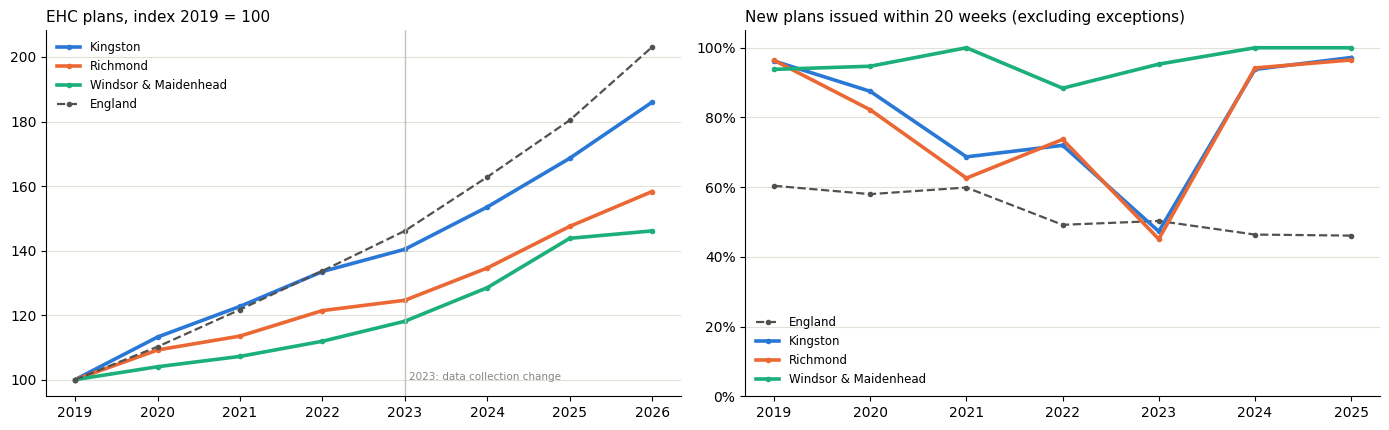

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
for area in list(TARGETS) + ["England"]:
    g = growth[growth["area"] == area]
    ax.plot(g["year"], g["index_first_year"], lw=2.6 if area != "England" else 1.6,
            ls="--" if area == "England" else "-", color=COLOURS[area], label=TARGETS.get(area, "England"), marker="o", ms=3)
ax.set_title(f"EHC plans, index {YEARS[0]} = 100", loc="left", fontsize=11)
ax.axvline(2023, color="#c3c2b7", lw=1); ax.text(2023.05, ax.get_ylim()[0] + 5, "2023: data collection change", fontsize=7.5, color="#898781")
ax.legend(frameon=False, fontsize=8.5); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e1e0d9")

ax = axes[1]
if len(tl):
    for area in tl.columns:
        ax.plot(tl.index, tl[area], lw=2.6 if area != "England" else 1.6, ls="--" if area == "England" else "-",
                color=COLOURS.get(area, "#999"), label=TARGETS.get(area, area), marker="o", ms=3)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, 105)
ax.set_title("New plans issued within 20 weeks (excluding exceptions)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e1e0d9")
plt.tight_layout(); plt.savefig(OUT / "repo" / "images" / "growth_and_timeliness.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Forecasting

### The challenge

There are only eight January snapshots per council (2019 to 2026), and DfE changed how the data was collected in 2023, which caused a step change in many councils' numbers. With so little history, a complex model would simply memorise noise. So the approach is:

1. **Try five simple, explainable models.**
2. **Test them fairly** on every council in England by *pretending to be in the past*: train on data up to, say, 2022, forecast 2023 to 2025, and compare with what actually happened. Repeat from every possible starting point. This is called **rolling-origin backtesting**.
3. **Pick the model with the smallest typical error** across all ~150 councils, rather than whichever fits one borough best. That's more robust with short series.
4. **Build the forecast range from real errors.** The spread of the backtest errors at each horizon gives an honest 80% range, rather than one that assumes the future will be well-behaved.

### The five models

| Model | Idea |
|:-|:-|
| **Naive** | Next year equals this year. Any useful model must beat this. |
| **Drift** | Continue the average yearly change since the first year. |
| **Linear (last 4 years)** | A straight-line trend through the most recent four years. |
| **Compound growth (last 3 years)** | Continue the recent average growth *rate*. |
| **Damped trend (Holt)** | A trend that gradually flattens, often the most realistic for demand that can't grow forever. |
| **Ensemble** | The average of drift, linear and compound growth. Averaging often cancels out individual models' mistakes. |

In [ ]:
def f_naive(y, h):  return np.repeat(y[-1], h).astype(float)
def f_drift(y, h):  return y[-1] + (y[-1] - y[0]) / (len(y) - 1) * np.arange(1, h + 1)
def f_linear(y, h, k=4):
    yy = y[-k:]; b, a = np.polyfit(np.arange(len(yy)), yy, 1)
    return a + b * np.arange(len(yy), len(yy) + h)
def f_growth(y, h, k=3):
    k = min(k, len(y) - 1)
    g = (y[-1] / y[-1 - k]) ** (1 / k) - 1 if y[-1 - k] > 0 else 0.0
    return y[-1] * (1 + g) ** np.arange(1, h + 1)
def f_damped(y, h):
    try:
        fit = ExponentialSmoothing(y.astype(float), trend="add", damped_trend=True, initialization_method="estimated").fit()
        out = np.asarray(fit.forecast(h), dtype=float)
        return out if np.all(np.isfinite(out)) else f_drift(y, h)
    except Exception:
        return f_drift(y, h)
def f_ensemble(y, h): return (f_drift(y, h) + f_linear(y, h) + f_growth(y, h)) / 3

MODELS = {"Naive": f_naive, "Drift": f_drift, "Linear (last 4 years)": f_linear,
          "Compound growth (last 3 years)": f_growth, "Damped trend (Holt)": f_damped, "Ensemble": f_ensemble}
print(f"{len(MODELS)} models ready.")

6 models ready.


### Rolling-origin backtest on every council

For each council, each starting point (with at least four years of training data) and each model, we forecast up to three years ahead and record the error.

* **APE** (absolute percentage error): how far off, ignoring direction.
* **Percentage error**: signed, so we can see whether a model tends to under- or over-forecast.

In [ ]:
MIN_TRAIN = 4
panel = stock[stock["level"] == "Local authority"].pivot(index="area", columns="year", values="plans").sort_index(axis=1)
rows = []
for area, s_ in panel.iterrows():
    s_ = s_.dropna()
    if len(s_) < MIN_TRAIN + 1:
        continue
    yrs, y = s_.index.to_numpy(), s_.to_numpy(dtype=float)
    for end in range(MIN_TRAIN - 1, len(y) - 1):
        h_max = min(HORIZON, len(y) - 1 - end)
        train = y[: end + 1]
        for name, f in MODELS.items():
            fc = f(train, h_max)
            for h in range(1, h_max + 1):
                actual, pred = y[end + h], fc[h - 1]
                rows.append((area, name, int(yrs[end]), h, actual, pred))

bt = pd.DataFrame(rows, columns=["area", "model", "origin", "horizon", "actual", "forecast"])
bt = bt[(bt["actual"] > 0) & (bt["forecast"] > 0)]
bt["ape"] = (bt["actual"] - bt["forecast"]).abs() / bt["actual"] * 100
bt["pe"] = (bt["actual"] - bt["forecast"]) / bt["forecast"] * 100      # positive = actual came in higher than forecast

summary = (bt.groupby(["model", "horizon"])["ape"].median().unstack().round(1))
summary.columns = [f"{c}-year-ahead error (median %)" for c in summary.columns]
summary["Average"] = summary.mean(axis=1).round(1)
summary["Bias (median %, + = under-forecast)"] = bt.groupby("model")["pe"].median().round(1)
summary = summary.sort_values("Average")
print(f"Backtest: {bt['area'].nunique()} councils, {len(bt):,} forecasts.")
summary

Backtest: 152 councils, 8,027 forecasts.


,1-year-ahead error (median %),2-year-ahead error (median %),3-year-ahead error (median %),Average,"Bias (median %, + = under-forecast)"
model,,,,,
Compound growth (last 3 years),3.3,6.4,9.7,6.5,1.4
Ensemble,3.5,7.1,10.6,7.1,3.7
Drift,3.8,7.4,11.4,7.5,4.8
Linear (last 4 years),4.1,7.8,11.5,7.8,5.0
Damped trend (Holt),4.0,8.3,11.5,7.9,5.4
Naive,9.6,18.8,26.6,18.3,17.0


**Why the median?** A few councils had very large jumps (often around the 2023 collection change). The median shows the *typical* error without letting a handful of unusual councils dominate. Positive bias means demand came in **higher** than the model predicted, which has been the national story for several years.

Chosen model: Compound growth (last 3 years)
Typical error: 3.3% one year ahead, rising to 9.7% three years ahead.
Naive model for comparison: 18.3% average error.


horizon,1-year-ahead error (median %),2-year-ahead error (median %),3-year-ahead error (median %)
area,,,
Kingston,1.9,4.2,6.0
Richmond,3.4,4.7,5.2
Windsor & Maidenhead,4.6,6.2,10.5


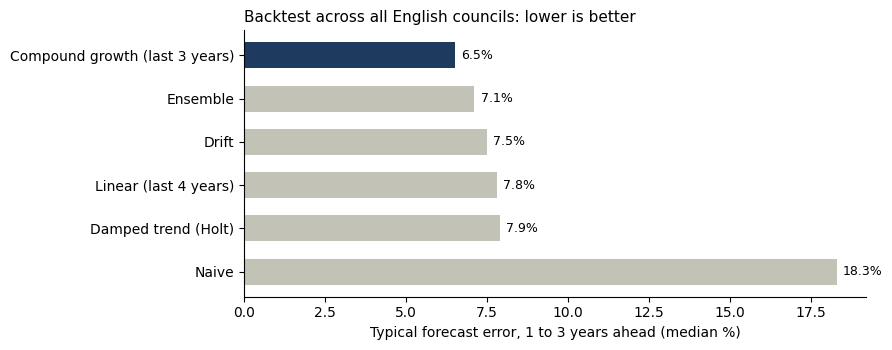

In [ ]:
BEST = summary.index[0]
print(f"Chosen model: {BEST}")
print(f"Typical error: {summary.loc[BEST].iloc[0]:.1f}% one year ahead, rising to {summary.loc[BEST].iloc[HORIZON - 1]:.1f}% three years ahead.")
print(f"Naive model for comparison: {summary.loc['Naive', 'Average']:.1f}% average error.")

# How did the chosen model do for our three boroughs specifically?
mine = bt[(bt["model"] == BEST) & bt["area"].isin(TARGETS)]
display(mine.groupby(["area", "horizon"])["ape"].median().unstack().round(1).rename(index=TARGETS)
        .rename(columns=lambda c: f"{c}-year-ahead error (median %)"))

fig, ax = plt.subplots(figsize=(9, 3.6))
order = summary.sort_values("Average", ascending=False)
ax.barh(order.index, order["Average"], color=["#1f3a5f" if m == BEST else "#c3c2b7" for m in order.index], height=0.6)
for i, v in enumerate(order["Average"]):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Typical forecast error, 1 to 3 years ahead (median %)")
ax.set_title("Backtest across all English councils: lower is better", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "repo" / "images" / "model_backtest.png", dpi=150, bbox_inches="tight"); plt.show()

### An honest forecast range

Instead of assuming errors follow a neat bell curve, we take the chosen model's **actual backtest errors** at each horizon and use the 10th and 90th percentiles. Roughly 8 times out of 10 in the past, the true figure landed inside this range.

In [ ]:
best_bt = bt[bt["model"] == BEST]
BANDS = {h: (np.percentile(g["pe"], 10), np.percentile(g["pe"], 90)) for h, g in best_bt.groupby("horizon")}
pd.DataFrame(BANDS, index=["Lower (10th pct, %)", "Upper (90th pct, %)"]).round(1).rename(columns=lambda h: f"{h} year(s) ahead")

,1 year(s) ahead,2 year(s) ahead,3 year(s) ahead
"Lower (10th pct, %)",-5.8,-9.3,-12.5
"Upper (90th pct, %)",7.2,14.5,21.2


## 7. The forecast

Each borough's full history is used to forecast January of the next three years with the chosen model, and the range from the backtest is applied.

In [ ]:
fc_rows = []
for area in list(TARGETS) + ["England"]:
    s_ = stock[stock["area"] == area].set_index("year")["plans"].dropna().sort_index()
    y = s_.to_numpy(dtype=float)
    for yr, v in s_.items():
        fc_rows.append((area, int(yr), "Actual", v, np.nan, np.nan))
    pred = MODELS[BEST](y, HORIZON)
    for h in range(1, HORIZON + 1):
        lo, hi = BANDS[h]
        p = pred[h - 1]
        fc_rows.append((area, int(LATEST + h), "Forecast", p, p * (1 + lo / 100), p * (1 + hi / 100)))
forecast = pd.DataFrame(fc_rows, columns=["area", "year", "type", "plans", "lower", "upper"])

table = []
for area in list(TARGETS) + ["England"]:
    f = forecast[forecast["area"] == area]
    now = f[f["year"] == LATEST]["plans"].iloc[0]
    end = f[f["year"] == LATEST + HORIZON].iloc[0]
    table.append({"Area": TARGETS.get(area, "England"), f"Jan {LATEST}": int(now),
                  f"Jan {LATEST + HORIZON} forecast": int(round(end["plans"])),
                  "Range (80%)": f"{int(round(end['lower'])):,} to {int(round(end['upper'])):,}",
                  "Change": f"+{int(round(end['plans'] - now)):,} ({(end['plans'] / now - 1) * 100:.0f}%)"})
headline = pd.DataFrame(table).set_index("Area")
headline

,Jan 2026,Jan 2029 forecast,Range (80%),Change
Area,,,,
Kingston,2159,2860,"2,502 to 3,466",+701 (32%)
Richmond,2166,2753,"2,409 to 3,337",+587 (27%)
Windsor & Maidenhead,1363,1686,"1,475 to 2,043",+323 (24%)
England,718838,999381,"874,360 to 1,211,204","+280,543 (39%)"


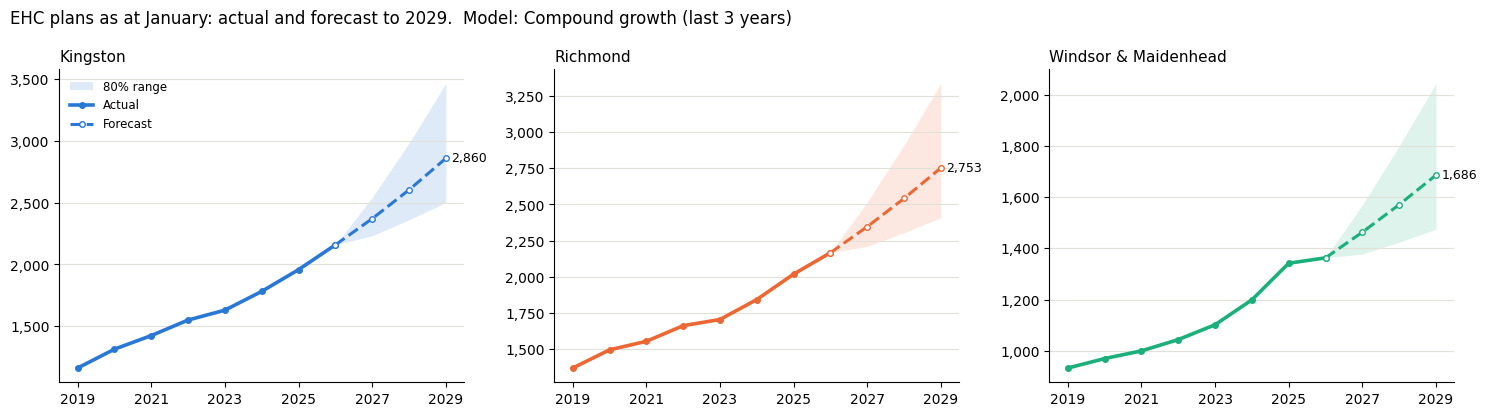

In [ ]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(15, 4.2), sharey=False)
for ax, area in zip(axes, TARGETS):
    f = forecast[forecast["area"] == area]
    a, p = f[f["type"] == "Actual"], f[f["type"] == "Forecast"]
    bridge = pd.concat([a.tail(1), p])
    ax.fill_between(bridge["year"], bridge["lower"].fillna(bridge["plans"]), bridge["upper"].fillna(bridge["plans"]),
                    color=COLOURS[area], alpha=0.15, lw=0, label="80% range")
    ax.plot(a["year"], a["plans"], color=COLOURS[area], lw=2.6, marker="o", ms=4, label="Actual")
    ax.plot(bridge["year"], bridge["plans"], color=COLOURS[area], lw=2.2, ls="--", marker="o", ms=4, mfc="white", label="Forecast")
    end = p.iloc[-1]
    ax.annotate(f"{end['plans']:,.0f}", (end["year"], end["plans"]), xytext=(4, 0), textcoords="offset points", fontsize=9, va="center")
    ax.set_title(TARGETS[area], loc="left", fontsize=11)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e1e0d9")
    ax.set_xticks(list(range(int(YEARS[0]), int(LATEST + HORIZON + 1), 2)))
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle(f"EHC plans as at January: actual and forecast to {LATEST + HORIZON}.  Model: {BEST}", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.savefig(OUT / "repo" / "images" / "forecast.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. So what? Turning the forecast into planning numbers

A forecast is only useful if it changes a decision. Three planning implications follow directly:

1. **Annual reviews.** Every EHC plan must be reviewed at least once a year, so the forecast number of plans is also the minimum number of annual reviews the service must complete.
2. **School places.** If each borough's placement mix stays as it is now, the forecast tells us how many more children will need a place in mainstream schools, special schools and independent special schools.
3. **Alternative Provision.** The same approach gives a first estimate for plans attended in alternative provision.

These are *scenarios*, not predictions of policy: if more children are supported in mainstream schools, the special school figures fall.

In [ ]:
latest_mix = stock[(stock["year"] == LATEST) & stock["area"].isin(TARGETS)].set_index("area")
SETTINGS = {"mainstream": "Mainstream schools", "special": "Special schools (all)",
            "special_independent": "Independent special schools", "alternative_provision": "Alternative provision"}
plan_rows = []
for area in TARGETS:
    now = latest_mix.loc[area, "plans"]
    fut = forecast[(forecast["area"] == area) & (forecast["year"] == LATEST + HORIZON)]["plans"].iloc[0]
    plan_rows.append({"Borough": TARGETS[area], "Measure": "Annual reviews needed per year (minimum)",
                      f"Jan {LATEST}": now, f"Jan {LATEST + HORIZON}": fut, "Extra": fut - now})
    for col, label in SETTINGS.items():
        share = latest_mix.loc[area, col] / now if pd.notna(latest_mix.loc[area, col]) and now else np.nan
        plan_rows.append({"Borough": TARGETS[area], "Measure": f"Plans in {label.lower()}",
                          f"Jan {LATEST}": latest_mix.loc[area, col], f"Jan {LATEST + HORIZON}": fut * share,
                          "Extra": fut * share - latest_mix.loc[area, col]})
planning = pd.DataFrame(plan_rows)
planning[[f"Jan {LATEST}", f"Jan {LATEST + HORIZON}", "Extra"]] = planning[[f"Jan {LATEST}", f"Jan {LATEST + HORIZON}", "Extra"]].round(0)
planning.set_index(["Borough", "Measure"])

Jan 2026  Jan 2029  Extra
Borough              Measure                                                            
Kingston             Annual reviews needed per year (minimum)    2159.0    2860.0  701.0
                     Plans in mainstream schools                 1022.0    1354.0  332.0
                     Plans in special schools (all)               631.0     836.0  205.0
                     Plans in independent special schools         103.0     136.0   33.0
                     Plans in alternative provision                74.0      98.0   24.0
Richmond             Annual reviews needed per year (minimum)    2166.0    2753.0  587.0
                     Plans in mainstream schools                 1199.0    1524.0  325.0
                     Plans in special schools (all)               508.0     646.0  138.0
                     Plans in independent special schools         143.0     182.0   39.0
                     Plans in alternative provision                61.0      78.0   17.0
Windsor & Maidenhead Annual reviews needed per year (minimum)    1363.0    1686.0  323.0
                     Plans in mainstream schools                  777.0     961.0  184.0
                     Plans in special schools (all)               368.0     455.0   87.0
                     Plans in independent special schools          88.0     109.0   21.0
                     Plans in alternative provision                19.0      23.0    4.0

## 9. Insight brief for senior managers

Generated from the results, so it always matches the data. Treat it as a first draft and add your own judgement.

In [ ]:
from IPython.display import Markdown

def n0(v): return f"{v:,.0f}"

def bias_note(b):
    if b > 1:
        return f"* In the backtest, demand came in {b:.1f}% above this model's forecast in a typical case, so planning should lean towards the upper end of the range."
    if b < -1:
        return f"* In the backtest, demand came in {abs(b):.1f}% below this model's forecast in a typical case, so the central figure may be slightly cautious on the high side."
    return f"* In the backtest this model showed no strong tendency to over- or under-forecast (median bias {b:+.1f}%)."
lg = league.set_index("area")

def borough_brief(area):
    name = TARGETS[area]
    f = forecast[forecast["area"] == area]
    now = f[f["year"] == LATEST]["plans"].iloc[0]
    end = f[f["year"] == LATEST + HORIZON].iloc[0]
    eng_now = forecast[(forecast["area"] == "England") & (forecast["year"] == LATEST)]["plans"].iloc[0]
    eng_end = forecast[(forecast["area"] == "England") & (forecast["year"] == LATEST + HORIZON)]["plans"].iloc[0]
    L = [f"### {name}", ""]
    L.append(f"* **Demand:** {n0(now)} EHC plans in January {LATEST}, forecast to reach **{n0(end['plans'])}** by January {LATEST + HORIZON} "
             f"(80% range {n0(end['lower'])} to {n0(end['upper'])}), an increase of {(end['plans'] / now - 1) * 100:.0f}%. "
             f"England is forecast to grow by {(eng_end / eng_now - 1) * 100:.0f}% over the same period.")
    if area in lg.index:
        r = lg.loc[area]
        L.append(f"* **Growth:** plans grew by {r['cagr_all_pct']:.1f}% a year on average since {YEARS[0]}, ranking {int(r['rank_all'])} of {int(r['councils'])} "
                 f"councils for growth (1 = fastest). Over the last three years: {r['cagr_3y_pct']:.1f}% a year.")
    m = mix[(mix["area"] == area) & (mix["year"] == LATEST)].iloc[0]
    e = mix[(mix["area"] == "England") & (mix["year"] == LATEST)].iloc[0]
    L.append(f"* **Placements:** {m['special_pct']:.0f}% of plans are in special schools (England {e['special_pct']:.0f}%), including "
             f"{m['independent_special_pct']:.0f}% in independent special schools (England {e['independent_special_pct']:.0f}%).")
    if len(timeliness):
        tt = timeliness[(timeliness["area"] == area)].sort_values("year").iloc[-1]
        te = timeliness[(timeliness["area"] == "England") & (timeliness["year"] == tt["year"])]["pct_within_20"]
        sn_txt = ""
        if len(tl_sn):
            sn = tl_sn[(tl_sn["area"] == area) & (tl_sn["year"] == tt["year"])]["neighbours_avg_pct"]
            sn_txt = f", neighbours {sn.iloc[0]:.0f}%" if len(sn) and pd.notna(sn.iloc[0]) else ""
        L.append(f"* **Timeliness:** {tt['pct_within_20']:.0f}% of new plans issued within 20 weeks in {int(tt['year'])} "
                 f"(England {te.iloc[0]:.0f}%{sn_txt}).")
    p = planning[planning["Borough"] == name].set_index("Measure")
    L.append(f"* **So what:** about **{n0(p.loc['Annual reviews needed per year (minimum)', 'Extra'])} more annual reviews a year** by {LATEST + HORIZON}. "
             f"If the placement mix stays the same, around {n0(p.loc['Plans in special schools (all)', 'Extra'])} more children will need a special school place, "
             f"including {n0(p.loc['Plans in independent special schools', 'Extra'])} in independent special schools, which are typically the most expensive placements.")
    L.append("")
    return "\n".join(L)

brief = "\n".join([
    f"# SEND demand forecast: insight brief, January {LATEST}", "",
    f"*Source: DfE Education, health and care plans (SEN2), reporting year {LATEST}. Forecast model: {BEST}, chosen by backtesting "
    f"across {bt['area'].nunique()} councils (typical error {summary.loc[BEST].iloc[0]:.1f}% one year ahead, {summary.loc[BEST].iloc[HORIZON - 1]:.1f}% three years ahead).*", "",
    *[borough_brief(a) for a in TARGETS],
    "### Caveats",
    "* Only eight years of data are available, and DfE changed its collection method in 2023, so the range matters as much as the central figure.",
    bias_note(summary.loc[BEST, "Bias (median %, + = under-forecast)"]),
    "* Placement figures assume today's mix continues. Policy choices, such as more resourced provision in mainstream schools, would change them.",
])
(OUT / "insight_brief.md").write_text(brief, encoding="utf-8")
Markdown(brief)

# SEND demand forecast: insight brief, January 2026

*Source: DfE Education, health and care plans (SEN2), reporting year 2026. Forecast model: Compound growth (last 3 years), chosen by backtesting across 152 councils (typical error 3.3% one year ahead, 9.7% three years ahead).*

### Kingston

* **Demand:** 2,159 EHC plans in January 2026, forecast to reach **2,860** by January 2029 (80% range 2,502 to 3,466), an increase of 32%. England is forecast to grow by 39% over the same period.
* **Growth:** plans grew by 9.3% a year on average since 2019, ranking 96 of 149 councils for growth (1 = fastest). Over the last three years: 9.8% a year.
* **Placements:** 29% of plans are in special schools (England 29%), including 5% in independent special schools (England 5%).
* **Timeliness:** 97% of new plans issued within 20 weeks in 2025 (England 46%).
* **So what:** about **701 more annual reviews a year** by 2029. If the placement mix stays the same, around 205 more children will need a special school place, including 33 in independent special schools, which are typically the most expensive placements.

### Richmond

* **Demand:** 2,166 EHC plans in January 2026, forecast to reach **2,753** by January 2029 (80% range 2,409 to 3,337), an increase of 27%. England is forecast to grow by 39% over the same period.
* **Growth:** plans grew by 6.8% a year on average since 2019, ranking 132 of 149 councils for growth (1 = fastest). Over the last three years: 8.3% a year.
* **Placements:** 24% of plans are in special schools (England 29%), including 7% in independent special schools (England 5%).
* **Timeliness:** 96% of new plans issued within 20 weeks in 2025 (England 46%).
* **So what:** about **587 more annual reviews a year** by 2029. If the placement mix stays the same, around 138 more children will need a special school place, including 39 in independent special schools, which are typically the most expensive placements.

### Windsor & Maidenhead

* **Demand:** 1,363 EHC plans in January 2026, forecast to reach **1,686** by January 2029 (80% range 1,475 to 2,043), an increase of 24%. England is forecast to grow by 39% over the same period.
* **Growth:** plans grew by 5.6% a year on average since 2019, ranking 137 of 149 councils for growth (1 = fastest). Over the last three years: 7.3% a year.
* **Placements:** 27% of plans are in special schools (England 29%), including 6% in independent special schools (England 5%).
* **Timeliness:** 100% of new plans issued within 20 weeks in 2025 (England 46%).
* **So what:** about **323 more annual reviews a year** by 2029. If the placement mix stays the same, around 87 more children will need a special school place, including 21 in independent special schools, which are typically the most expensive placements.

### Caveats
* Only eight years of data are available, and DfE changed its collection method in 2023, so the range matters as much as the central figure.
* In the backtest, demand came in 1.4% above this model's forecast in a typical case, so planning should lean towards the upper end of the range.
* Placement figures assume today's mix continues. Policy choices, such as more resourced provision in mainstream schools, would change them.

## 10. Export

* `outputs/powerbi/`: tidy CSVs for the Power BI report
* `outputs/repo/`: ready for GitHub: `README.md`, `dashboard_data.js` and `.json` for `index.html`, chart images, insight brief

In [ ]:
pb = OUT / "powerbi"
stock.to_csv(pb / "fact_ehcp_stock.csv", index=False)
new_plans.merge(requests, on=["year", "level", "area"], how="outer").merge(
    timeliness[["year", "level", "area", "issued_ex", "within_20_ex", "pct_within_20"]], on=["year", "level", "area"], how="outer"
).to_csv(pb / "fact_pipeline.csv", index=False)
forecast.to_csv(pb / "fact_forecast.csv", index=False)
summary.reset_index().to_csv(pb / "model_backtest.csv", index=False)
planning.to_csv(pb / "planning_scenarios.csv", index=False)
league.to_csv(pb / "growth_league.csv", index=False)
pd.DataFrame([(t, s) for t, s in TARGETS.items()], columns=["area", "short_name"]).to_csv(pb / "dim_target.csv", index=False)
if HAS_SN:
    q("SELECT * FROM neighbours").to_csv(pb / "neighbours.csv", index=False)
for f in sorted(pb.glob("*.csv")):
    print(f"  {f.name:<24} {sum(1 for _ in open(f)) - 1:>6,} rows")

  dim_target.csv                3 rows
  fact_ehcp_stock.csv       1,297 rows
  fact_forecast.csv            44 rows
  fact_pipeline.csv         1,135 rows
  growth_league.csv           149 rows
  model_backtest.csv            6 rows
  planning_scenarios.csv       15 rows


In [ ]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (float, np.floating)): return None if not np.isfinite(o) else round(float(o), 2)
    return o

def series_of(df, area, col):
    d = df[df["area"] == area].dropna(subset=[col])
    return {str(int(y)): v for y, v in zip(d["year"], d[col])}

dash = {
    "meta": {"latest": int(LATEST), "horizon": HORIZON, "years": [int(y) for y in YEARS], "model": BEST,
             "n_councils": int(bt["area"].nunique()), "generated": pd.Timestamp.today().strftime("%d %B %Y"), "author": "Sara Iqbal"},
    "targets": [{"name": t, "short": s, "colour": COLOURS[t], "neighbours": NEIGHBOURS.get(t, [])} for t, s in TARGETS.items()],
    "forecast": forecast.to_dict(orient="records"),
    "backtest": summary.reset_index().rename(columns=lambda c: str(c)).to_dict(orient="records"),
    "bands": {str(h): list(v) for h, v in BANDS.items()},
    "timeliness": {a: series_of(timeliness, a, "pct_within_20") for a in list(TARGETS) + ["England"]},
    "timeliness_sn": {a: series_of(tl_sn, a, "neighbours_avg_pct") for a in TARGETS} if len(tl_sn) else {},
    "new_plans": {a: series_of(new_plans, a, "new_plans") for a in list(TARGETS) + ["England"]},
    "requests": {a: series_of(requests, a, "requests") for a in list(TARGETS) + ["England"]},
    "mix": mix[mix["year"] == LATEST].to_dict(orient="records"),
    "league": league[league["area"].isin(TARGETS)].to_dict(orient="records"),
    "planning": planning.to_dict(orient="records"),
}
dash = clean(dash)
with open(OUT / "repo" / "dashboard_data.json", "w") as f:
    json.dump(dash, f, indent=1)
with open(OUT / "repo" / "dashboard_data.js", "w") as f:
    f.write("window.DASHBOARD_DATA = " + json.dumps(dash) + ";")
print("Saved dashboard_data.json and dashboard_data.js")

Saved dashboard_data.json and dashboard_data.js


### Generate the README

The explanation is written once; every number is filled in from the results. Read it through before publishing and make the wording your own.

In [ ]:
def headline_md():
    out = ["| Borough | January " + str(LATEST) + " | January " + str(LATEST + HORIZON) + " forecast | 80% range | Change |",
           "| :- | -: | -: | -: | -: |"]
    for area, r in headline.iterrows():
        out.append(f"| {area} | {r.iloc[0]:,} | {r.iloc[1]:,} | {r.iloc[2]} | {r.iloc[3]} |")
    return "\n".join(out)

def backtest_md():
    out = ["| Model | 1 year ahead | 2 years ahead | 3 years ahead | Average |", "| :- | -: | -: | -: | -: |"]
    for m, r in summary.iterrows():
        mark = " **(chosen)**" if m == BEST else ""
        out.append(f"| {m}{mark} | {r.iloc[0]:.1f}% | {r.iloc[1]:.1f}% | {r.iloc[2]:.1f}% | {r['Average']:.1f}% |")
    return "\n".join(out)

findings = brief.split("### Caveats")[0].split("\n", 3)[-1].replace("### ", "#### ").strip()

readme = f'''# Forecasting SEND demand: Kingston, Richmond and Windsor & Maidenhead

**A three-year forecast of Education, Health and Care Plans using DfE statutory data, Python, SQL and Power BI.**

[Live dashboard](https://<your-username>.github.io/<repository-name>/) · [Notebook](send_ehcp_forecast.ipynb) · [Insight brief](insight_brief.md)

![Forecast](images/forecast.png)

## The problem

An Education, Health and Care Plan (EHCP) is a legal document that sets out the support a child or young person with special educational needs and disabilities must receive. Councils have to assess, issue, fund and review every plan, every year.

Demand is rising quickly. England had 718,838 plans in January 2026, 12.5% more than a year before, and fewer than half of new plans were issued within the statutory 20 weeks in 2025. For a children's services organisation the practical questions are simple to ask and hard to answer: **how many plans will we be responsible for in three years, where will those children be educated, and are we keeping up?**

I built this project to answer those questions for the three boroughs served by Achieving for Children.

## How I approached it

**1. Data.** I used the DfE's *Education, health and care plans* release (reporting year {LATEST}), which comes from the SEN2 statutory return every council submits. The notebook recognises each file by its columns rather than its name, keeps only the totals, and treats suppressed values as missing rather than zero.

**2. SQL.** I loaded the cleaned tables into SQLite and did the analysis in SQL: window functions for year-on-year growth and indexing, a CTE with `RANK()` to place each borough among all {len(ALL_LAS)} councils, joins across requests, new plans and timeliness to follow the pipeline, and a join to the DfE statistical neighbour list for fair comparisons.

**3. Forecasting.** With only eight January snapshots and a change in DfE's collection method in 2023, a complex model would just memorise noise. I compared six simple, explainable approaches and tested them fairly with **rolling-origin backtesting** on every council in England: train on the past, forecast the next three years, and compare with what actually happened. The model with the lowest typical error across all councils was chosen, and the forecast range comes from its real past errors rather than an assumption.

**4. So what.** I translated the forecast into planning numbers a manager can use: the extra annual reviews each year, and the extra special school and independent special school places needed if the placement mix stays the same.

## Results

### Which model?

Typical (median) error across {bt['area'].nunique()} councils:

{backtest_md()}

![Model backtest](images/model_backtest.png)

### The forecast

{headline_md()}

### What it means

{findings}

![Growth and timeliness](images/growth_and_timeliness.png)

## What I learned

**Simple, tested models beat clever, untested ones.** The most useful thing in this project is not the forecast itself but the evidence that the chosen method has worked in the past, across many councils.

**The range matters as much as the number.** A single figure gives false confidence. Showing an 80% range, built from real errors, lets a manager plan for a realistic high and low case.

**Bias is a finding.** The backtest shows whether demand has tended to come in above forecast. If it has, planning should lean towards the upper end of the range.

**A forecast has to lead to a decision.** Turning plans into annual reviews and school places is what makes the analysis useful to the people running the service.

## Limitations

* Eight years of data, with a collection change in 2023.
* The placement scenarios assume today's mix continues.
* The forecast is for plan numbers. Costs, staffing and sufficiency of places would need local data.

## Run it yourself

1. Download the *Education, health and care plans* "Download all data" zip from Explore Education Statistics (and optionally the statistical neighbour workbook from GOV.UK).
2. Open the notebook in Google Colab and select **Runtime > Run all**.

## Tools

Python (pandas, NumPy, statsmodels, Matplotlib), SQL (SQLite), Power BI, Chart.js, Google Colab, GitHub Pages.

*Built by Sara Iqbal (MSc Data Science). Contains public sector information licensed under the Open Government Licence v3.0.*
'''
(OUT / "repo" / "README.md").write_text(readme, encoding="utf-8")
shutil.copy(OUT / "insight_brief.md", OUT / "repo" / "insight_brief.md")
print("README written.")
Markdown(readme)

README written.


# Forecasting SEND demand: Kingston, Richmond and Windsor & Maidenhead

**A three-year forecast of Education, Health and Care Plans using DfE statutory data, Python, SQL and Power BI.**

[Live dashboard](https://<your-username>.github.io/<repository-name>/) · [Notebook](send_ehcp_forecast.ipynb) · [Insight brief](insight_brief.md)

![Forecast](images/forecast.png)

## The problem

An Education, Health and Care Plan (EHCP) is a legal document that sets out the support a child or young person with special educational needs and disabilities must receive. Councils have to assess, issue, fund and review every plan, every year.

Demand is rising quickly. England had 718,838 plans in January 2026, 12.5% more than a year before, and fewer than half of new plans were issued within the statutory 20 weeks in 2025. For a children's services organisation the practical questions are simple to ask and hard to answer: **how many plans will we be responsible for in three years, where will those children be educated, and are we keeping up?**

I built this project to answer those questions for the three boroughs served by Achieving for Children.

## How I approached it

**1. Data.** I used the DfE's *Education, health and care plans* release (reporting year 2026), which comes from the SEN2 statutory return every council submits. The notebook recognises each file by its columns rather than its name, keeps only the totals, and treats suppressed values as missing rather than zero.

**2. SQL.** I loaded the cleaned tables into SQLite and did the analysis in SQL: window functions for year-on-year growth and indexing, a CTE with `RANK()` to place each borough among all 157 councils, joins across requests, new plans and timeliness to follow the pipeline, and a join to the DfE statistical neighbour list for fair comparisons.

**3. Forecasting.** With only eight January snapshots and a change in DfE's collection method in 2023, a complex model would just memorise noise. I compared six simple, explainable approaches and tested them fairly with **rolling-origin backtesting** on every council in England: train on the past, forecast the next three years, and compare with what actually happened. The model with the lowest typical error across all councils was chosen, and the forecast range comes from its real past errors rather than an assumption.

**4. So what.** I translated the forecast into planning numbers a manager can use: the extra annual reviews each year, and the extra special school and independent special school places needed if the placement mix stays the same.

## Results

### Which model?

Typical (median) error across 152 councils:

| Model | 1 year ahead | 2 years ahead | 3 years ahead | Average |
| :- | -: | -: | -: | -: |
| Compound growth (last 3 years) **(chosen)** | 3.3% | 6.4% | 9.7% | 6.5% |
| Ensemble | 3.5% | 7.1% | 10.6% | 7.1% |
| Drift | 3.8% | 7.4% | 11.4% | 7.5% |
| Linear (last 4 years) | 4.1% | 7.8% | 11.5% | 7.8% |
| Damped trend (Holt) | 4.0% | 8.3% | 11.5% | 7.9% |
| Naive | 9.6% | 18.8% | 26.6% | 18.3% |

![Model backtest](images/model_backtest.png)

### The forecast

| Borough | January 2026 | January 2029 forecast | 80% range | Change |
| :- | -: | -: | -: | -: |
| Kingston | 2,159 | 2,860 | 2,502 to 3,466 | +701 (32%) |
| Richmond | 2,166 | 2,753 | 2,409 to 3,337 | +587 (27%) |
| Windsor & Maidenhead | 1,363 | 1,686 | 1,475 to 2,043 | +323 (24%) |
| England | 718,838 | 999,381 | 874,360 to 1,211,204 | +280,543 (39%) |

### What it means

#### Kingston

* **Demand:** 2,159 EHC plans in January 2026, forecast to reach **2,860** by January 2029 (80% range 2,502 to 3,466), an increase of 32%. England is forecast to grow by 39% over the same period.
* **Growth:** plans grew by 9.3% a year on average since 2019, ranking 96 of 149 councils for growth (1 = fastest). Over the last three years: 9.8% a year.
* **Placements:** 29% of plans are in special schools (England 29%), including 5% in independent special schools (England 5%).
* **Timeliness:** 97% of new plans issued within 20 weeks in 2025 (England 46%).
* **So what:** about **701 more annual reviews a year** by 2029. If the placement mix stays the same, around 205 more children will need a special school place, including 33 in independent special schools, which are typically the most expensive placements.

#### Richmond

* **Demand:** 2,166 EHC plans in January 2026, forecast to reach **2,753** by January 2029 (80% range 2,409 to 3,337), an increase of 27%. England is forecast to grow by 39% over the same period.
* **Growth:** plans grew by 6.8% a year on average since 2019, ranking 132 of 149 councils for growth (1 = fastest). Over the last three years: 8.3% a year.
* **Placements:** 24% of plans are in special schools (England 29%), including 7% in independent special schools (England 5%).
* **Timeliness:** 96% of new plans issued within 20 weeks in 2025 (England 46%).
* **So what:** about **587 more annual reviews a year** by 2029. If the placement mix stays the same, around 138 more children will need a special school place, including 39 in independent special schools, which are typically the most expensive placements.

#### Windsor & Maidenhead

* **Demand:** 1,363 EHC plans in January 2026, forecast to reach **1,686** by January 2029 (80% range 1,475 to 2,043), an increase of 24%. England is forecast to grow by 39% over the same period.
* **Growth:** plans grew by 5.6% a year on average since 2019, ranking 137 of 149 councils for growth (1 = fastest). Over the last three years: 7.3% a year.
* **Placements:** 27% of plans are in special schools (England 29%), including 6% in independent special schools (England 5%).
* **Timeliness:** 100% of new plans issued within 20 weeks in 2025 (England 46%).
* **So what:** about **323 more annual reviews a year** by 2029. If the placement mix stays the same, around 87 more children will need a special school place, including 21 in independent special schools, which are typically the most expensive placements.

![Growth and timeliness](images/growth_and_timeliness.png)

## What I learned

**Simple, tested models beat clever, untested ones.** The most useful thing in this project is not the forecast itself but the evidence that the chosen method has worked in the past, across many councils.

**The range matters as much as the number.** A single figure gives false confidence. Showing an 80% range, built from real errors, lets a manager plan for a realistic high and low case.

**Bias is a finding.** The backtest shows whether demand has tended to come in above forecast. If it has, planning should lean towards the upper end of the range.

**A forecast has to lead to a decision.** Turning plans into annual reviews and school places is what makes the analysis useful to the people running the service.

## Limitations

* Eight years of data, with a collection change in 2023.
* The placement scenarios assume today's mix continues.
* The forecast is for plan numbers. Costs, staffing and sufficiency of places would need local data.

## Run it yourself

1. Download the *Education, health and care plans* "Download all data" zip from Explore Education Statistics (and optionally the statistical neighbour workbook from GOV.UK).
2. Open the notebook in Google Colab and select **Runtime > Run all**.

## Tools

Python (pandas, NumPy, statsmodels, Matplotlib), SQL (SQLite), Power BI, Chart.js, Google Colab, GitHub Pages.

*Built by Sara Iqbal (MSc Data Science). Contains public sector information licensed under the Open Government Licence v3.0.*


In [ ]:
shutil.make_archive("send_forecast_outputs", "zip", OUT)
if IN_COLAB:
    colab_files.download("send_forecast_outputs.zip")
else:
    print("Saved send_forecast_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What next

* **Add population projections** (ONS sub-national projections) to turn plan numbers into rates and separate population growth from changes in identification.
* **Forecast by age group**, because plans for 16 to 25 year olds have grown fastest nationally and need different provision.
* **Track Alternative Provision outcomes** locally, to evidence whether earlier intervention reduces the need for a plan.